<a href="https://colab.research.google.com/github/srabani-khuntia/Machine-Learning-Lab/blob/main/Assignment-4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **ASSIGNMENT - 4: Naive Bayes & SVM Models**

In [ ]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Classification algorithms
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC

# Regression algorithm
from sklearn.svm import LinearSVR

# Evaluation metrics
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    auc,
    classification_report,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


##### **1. After preprocessing, split the dataset as training dataset 80% and test dataset 20%. Implement Naïve Bay’s classifier and measures its performances such as Confusion Matrix, Precision, Recall, accuracy, f1-score and ROC curve. Give the conclusion statements according to the performances of the model.**

In [ ]:
# Loading the classification dataset
from google.colab import files

uploaded = files.upload()
campus_df = pd.read_csv('campus_preprocessed.csv')

print("Dataset loaded successfully!")

Saving campus_preprocessed.csv to campus_preprocessed (1).csv
Dataset loaded successfully!


In [ ]:
display(campus_df.head())

,age,ssc_percentage,hsc_percentage,degree_percentage,mba_percentage,internships_count,projects_count,certifications_count,technical_skills_score,soft_skills_score,...,hsc_board_State,hsc_stream_Commerce,hsc_stream_Science,degree_field_Business,degree_field_Engineering,degree_field_Other,degree_field_Science,specialization_Marketing & Finance,specialization_Marketing & HR,specialization_Not Applicable
0,22,71.01,76.76,64.44,0.0,1,2,2,6.8,7.8,...,0,1,0,0,1,0,0,0,0,1
1,22,58.46,57.62,68.24,0.0,1,1,2,4.6,4.8,...,1,0,1,1,0,0,0,0,0,1
2,21,67.83,65.67,52.33,0.0,4,3,2,4.7,5.0,...,1,1,0,0,1,0,0,0,0,1
3,21,80.40,77.15,56.55,0.0,2,3,3,6.8,7.6,...,1,0,1,0,1,0,0,0,0,1
4,21,66.10,62.81,78.93,0.0,1,4,2,7.0,5.7,...,0,0,1,0,1,0,0,0,0,1


In [ ]:
# Separate independent and dependent variables
X = campus_df.drop(columns=['placed'])
y = campus_df['placed']

print("Independent Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

Independent Features Shape: (100000, 33)
Target Variable Shape: (100000,)


In [ ]:
# Train-Test Split

# Splitting the dataset into 80% training and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset dimensions
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Dataset Percentage:",
      round(len(X_train) / len(X) * 100, 2), "%")

print("Testing Dataset Percentage:",
      round(len(X_test) / len(X) * 100, 2), "%")

Training Features: (80000, 33)
Testing Features: (20000, 33)
Training Target: (80000,)
Testing Target: (20000,)

Training Dataset Percentage: 80.0 %
Testing Dataset Percentage: 20.0 %


In [ ]:
# Feature Scaling

# Initialize StandardScaler
scaler = StandardScaler()

# Fit scaler on training data and transform training features
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing features using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")
print("Scaled Training Shape:", X_train_scaled.shape)
print("Scaled Testing Shape:", X_test_scaled.shape)

Feature scaling completed successfully!
Scaled Training Shape: (80000, 33)
Scaled Testing Shape: (20000, 33)


### Implementation of Gaussian Naïve Bayes

Gaussian Naïve Bayes is a supervised machine learning algorithm based on Bayes' theorem. It assumes that the features are conditionally independent given the class and that continuous features follow a Gaussian (normal) distribution within each class.

In this implementation, Gaussian Naïve Bayes is used to predict whether a student will be placed or not placed.

In [ ]:
# Initialize Gaussian Naïve Bayes Classifier
nb_model = GaussianNB()

# Train the model
nb_model.fit(X_train_scaled, y_train)

print("Gaussian Naïve Bayes Classifier trained successfully!")

Gaussian Naïve Bayes Classifier trained successfully!


In [ ]:
# Predict class labels
y_pred_nb = nb_model.predict(X_test_scaled)

# Predict probabilities for positive class
y_prob_nb = nb_model.predict_proba(X_test_scaled)[:, 1]

print("Predictions generated successfully!")

print("\nFirst 10 Actual Values:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Values:")
print(y_pred_nb[:10])

Predictions generated successfully!

First 10 Actual Values:
[1 0 1 0 1 1 1 1 1 1]

First 10 Predicted Values:
[1 0 1 0 1 1 1 1 1 1]


In [ ]:
# Calculate evaluation metrics
nb_accuracy = accuracy_score(y_test, y_pred_nb)

nb_precision = precision_score(
    y_test, y_pred_nb, zero_division=0
)

nb_recall = recall_score(
    y_test, y_pred_nb, zero_division=0
)

nb_f1 = f1_score(
    y_test, y_pred_nb, zero_division=0
)

print("NAÏVE BAYES CLASSIFIER PERFORMANCE")
print("-" * 40)

print("Accuracy :", round(nb_accuracy, 4))
print("Precision:", round(nb_precision, 4))
print("Recall   :", round(nb_recall, 4))
print("F1-Score :", round(nb_f1, 4))

NAÏVE BAYES CLASSIFIER PERFORMANCE
----------------------------------------
Accuracy : 0.8321
Precision: 0.9011
Recall   : 0.8999
F1-Score : 0.9005


Confusion Matrix:
[[ 1447  1667]
 [ 1691 15195]]


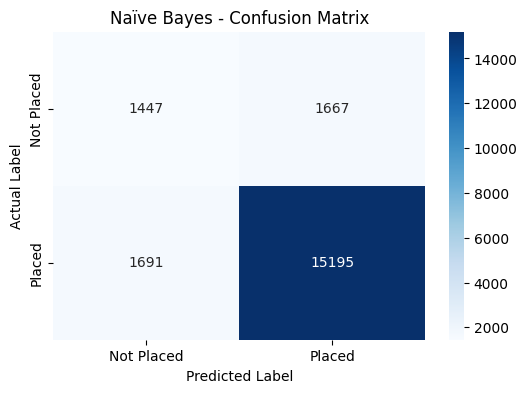

In [ ]:
# Generate confusion matrix
cm_nb = confusion_matrix(y_test, y_pred_nb)

print("Confusion Matrix:")
print(cm_nb)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Placed', 'Placed'],
    yticklabels=['Not Placed', 'Placed']
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Naïve Bayes - Confusion Matrix")
plt.show()

In [ ]:
# Generate classification report
print("Naïve Bayes Classification Report:")

print(
    classification_report(
        y_test,
        y_pred_nb,
        target_names=['Not Placed', 'Placed'],
        zero_division=0
    )
)

Naïve Bayes Classification Report:
              precision    recall  f1-score   support

  Not Placed       0.46      0.46      0.46      3114
      Placed       0.90      0.90      0.90     16886

    accuracy                           0.83     20000
   macro avg       0.68      0.68      0.68     20000
weighted avg       0.83      0.83      0.83     20000



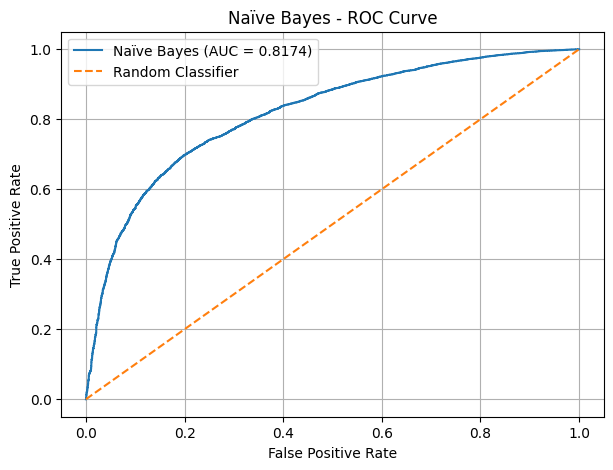

Naïve Bayes AUC Score: 0.8174


In [ ]:
# Calculate False Positive Rate and True Positive Rate
fpr_nb, tpr_nb, thresholds_nb = roc_curve(
    y_test,
    y_prob_nb
)

# Calculate Area Under the Curve
auc_nb = auc(fpr_nb, tpr_nb)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr_nb,
    tpr_nb,
    label=f'Naïve Bayes (AUC = {auc_nb:.4f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Naïve Bayes - ROC Curve")
plt.legend()
plt.grid()
plt.show()

print("Naïve Bayes AUC Score:", round(auc_nb, 4))

### Conclusion – Naïve Bayes Classifier

- Achieved an accuracy of **83.21%**, indicating good overall classification performance.
- Obtained a precision of **90.11%** and recall of **89.99%** for the Placed class.
- Achieved an F1-score of **90.05%**, indicating a good balance between precision and recall.
- Obtained a ROC-AUC score of **0.8174**, demonstrating good class discrimination.
- Correctly classified 15,195 placed students and 1,447 students who were not placed.
- The model showed balanced precision and recall for the Placed class but had comparatively lower performance in identifying the Not Placed class.

##### **2. After preprocessing, split the dataset as training dataset 80% and test dataset 20%. Implement support vector classifier and measures its performances such as Confusion Matrix, Precision, Recall, accuracy, f1-score and ROC curve. Give the conclusion statements according to the performances of the model.**

### Implementation of Support Vector Classifier

A Support Vector Machine (SVM) is a supervised machine learning algorithm that finds an optimal decision boundary, known as a hyperplane, to separate different classes.

Feature scaling is applied because SVM is sensitive to the scale of input features.

The model's performance is evaluated using Confusion Matrix, Accuracy, Precision, Recall, F1-Score and ROC Curve.

In [ ]:
# Initialize Linear Support Vector Classifier
svc_model = LinearSVC(
    C=1.0,
    max_iter=10000,
    random_state=42
)

# Train the model
svc_model.fit(X_train_scaled, y_train)

print("Support Vector Classifier trained successfully!")

Support Vector Classifier trained successfully!


In [ ]:
# Predict class labels
y_pred_svc = svc_model.predict(X_test_scaled)

# Obtain decision scores for ROC curve
y_score_svc = svc_model.decision_function(X_test_scaled)

print("Predictions generated successfully!")

print("\nFirst 10 Actual Values:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Values:")
print(y_pred_svc[:10])

Predictions generated successfully!

First 10 Actual Values:
[1 0 1 0 1 1 1 1 1 1]

First 10 Predicted Values:
[1 1 1 0 1 1 1 1 1 1]


In [ ]:
# Calculate evaluation metrics
svc_accuracy = accuracy_score(y_test, y_pred_svc)

svc_precision = precision_score(
    y_test, y_pred_svc, zero_division=0
)

svc_recall = recall_score(
    y_test, y_pred_svc, zero_division=0
)

svc_f1 = f1_score(
    y_test, y_pred_svc, zero_division=0
)

print("SUPPORT VECTOR CLASSIFIER PERFORMANCE")
print("-" * 45)

print("Accuracy :", round(svc_accuracy, 4))
print("Precision:", round(svc_precision, 4))
print("Recall   :", round(svc_recall, 4))
print("F1-Score :", round(svc_f1, 4))

SUPPORT VECTOR CLASSIFIER PERFORMANCE
---------------------------------------------
Accuracy : 0.8576
Precision: 0.8671
Recall   : 0.9818
F1-Score : 0.9209


Confusion Matrix:
[[  573  2541]
 [  308 16578]]


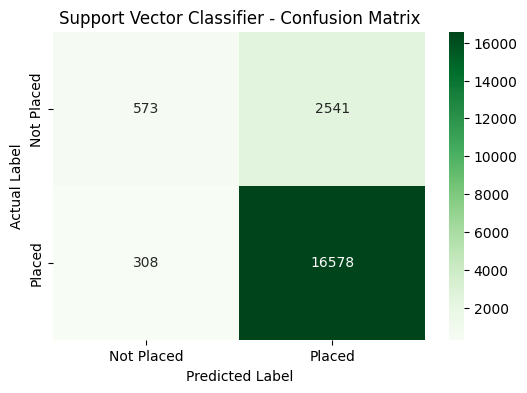

In [ ]:
# Generate confusion matrix
cm_svc = confusion_matrix(y_test, y_pred_svc)

print("Confusion Matrix:")
print(cm_svc)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_svc,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Not Placed', 'Placed'],
    yticklabels=['Not Placed', 'Placed']
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Support Vector Classifier - Confusion Matrix")
plt.show()

In [ ]:
# Generate classification report
print("Support Vector Classifier Classification Report:")

print(
    classification_report(
        y_test,
        y_pred_svc,
        target_names=['Not Placed', 'Placed'],
        zero_division=0
    )
)

Support Vector Classifier Classification Report:
              precision    recall  f1-score   support

  Not Placed       0.65      0.18      0.29      3114
      Placed       0.87      0.98      0.92     16886

    accuracy                           0.86     20000
   macro avg       0.76      0.58      0.60     20000
weighted avg       0.83      0.86      0.82     20000



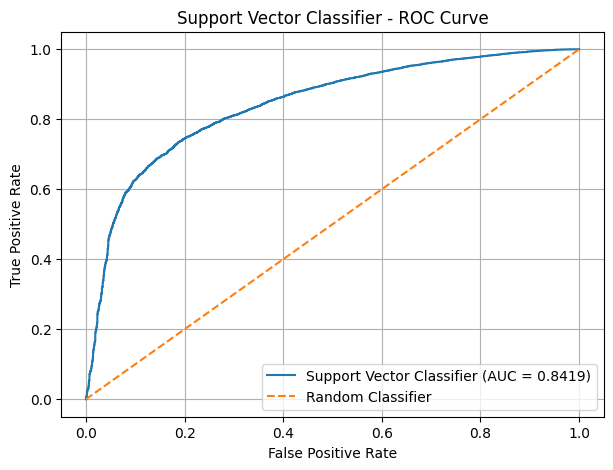

Support Vector Classifier AUC Score: 0.8419


In [ ]:
# Calculate False Positive Rate and True Positive Rate
fpr_svc, tpr_svc, thresholds_svc = roc_curve(
    y_test,
    y_score_svc
)

# Calculate Area Under the Curve
auc_svc = auc(fpr_svc, tpr_svc)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr_svc,
    tpr_svc,
    label=f'Support Vector Classifier (AUC = {auc_svc:.4f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Support Vector Classifier - ROC Curve")
plt.legend()
plt.grid()
plt.show()

print("Support Vector Classifier AUC Score:", round(auc_svc, 4))

### Conclusion – Support Vector Classifier

- Achieved an accuracy of **85.76%**, indicating good overall classification performance.
- Obtained a precision of **86.71%** and recall of **98.18%** for the Placed class.
- Achieved an F1-score of **92.09%**, indicating strong classification performance.
- Obtained a ROC-AUC score of **0.8419**, demonstrating good class discrimination.
- Correctly classified 16,578 placed students but only 573 students who were not placed.
- The model demonstrated high recall for the Placed class but struggled to identify the minority class (Not Placed).

In [ ]:
# Create a comparison table
classification_results = pd.DataFrame({
    'Algorithm': [
        'Gaussian Naïve Bayes',
        'Linear Support Vector Classifier'
    ],
    'Accuracy': [
        nb_accuracy,
        svc_accuracy
    ],
    'Precision': [
        nb_precision,
        svc_precision
    ],
    'Recall': [
        nb_recall,
        svc_recall
    ],
    'F1-Score': [
        nb_f1,
        svc_f1
    ],
    'AUC': [
        auc_nb,
        auc_svc
    ]
})

display(
    classification_results.sort_values(
        by='F1-Score',
        ascending=False
    ).reset_index(drop=True)
)

,Algorithm,Accuracy,Precision,Recall,F1-Score,AUC
0,Linear Support Vector Classifier,0.85755,0.867096,0.981760,0.920872,0.841922
1,Gaussian Naïve Bayes,0.83210,0.901139,0.899858,0.900498,0.817423


### Overall Conclusion – Classification

- Gaussian Naïve Bayes and Linear Support Vector Classifier were successfully implemented and evaluated using the same **80:20 training-testing split**.
- Their performances were compared using Accuracy, Precision, Recall, F1-Score and ROC-AUC.
- **Linear Support Vector Classifier** achieved better overall performance, with higher accuracy (**85.76%**), F1-score (**92.09%**) and ROC-AUC (**0.8419**).
- Gaussian Naïve Bayes achieved higher precision (**90.11%**) but comparatively lower accuracy, recall, F1-score and ROC-AUC.
- Both models showed difficulty in identifying students belonging to the Not Placed category due to the imbalanced target distribution.
- Therefore, Linear Support Vector Classifier demonstrated better overall classification performance among the two algorithms.

##### **3. After preprocessing, split the dataset as training dataset 80% and test dataset 20%. Implement support vector regressor and measures its performances such as MAE, MSE, RMSE, and R2. Give the conclusion statements according to the performances of the model.**

### Implementation of Support Vector Regressor

Support Vector Regression (SVR) is a supervised machine learning algorithm used for regression problems. It attempts to find a function that predicts target values while keeping prediction errors within a specified margin called the epsilon tube.

Feature scaling is applied because SVR is sensitive to the scale of input features.

The model's performance is evaluated using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE) and R² Score.

In [ ]:
# Loading the regression dataset

from google.colab import files
uploaded = files.upload()

uber_df = pd.read_csv('uber_preprocessed.csv')
print("Dataset loaded successfully!")

Saving uber_preprocessed.csv to uber_preprocessed (1).csv
Dataset loaded successfully!


In [ ]:
display(uber_df.head())

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,pickup_year,pickup_month,pickup_day,pickup_dayofweek,pickup_hour
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,2015,5,7,3,19
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,2009,7,17,4,20
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,2009,8,24,0,21
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,2009,6,26,4,8
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,2014,8,28,3,17


In [ ]:
# Separate independent features and target variable
X = uber_df.drop(columns=['fare_amount'])
y = uber_df['fare_amount']

print("Independent Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

Independent Features Shape: (194918, 10)
Target Variable Shape: (194918,)


In [ ]:
# Train-Test Split

# Splitting the dataset into 80% training and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Display dataset dimensions
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Dataset Percentage:",
      round(len(X_train) / len(X) * 100, 2), "%")

print("Testing Dataset Percentage:",
      round(len(X_test) / len(X) * 100, 2), "%")

Training Features: (155934, 10)
Testing Features: (38984, 10)
Training Target: (155934,)
Testing Target: (38984,)

Training Dataset Percentage: 80.0 %
Testing Dataset Percentage: 20.0 %


In [ ]:
# Feature Scaling

# Initialize StandardScaler
scaler = StandardScaler()

# Fit scaler on training data and transform training features
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing features using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

print("Scaled Training Shape:", X_train_scaled.shape)
print("Scaled Testing Shape:", X_test_scaled.shape)

Feature scaling completed successfully!
Scaled Training Shape: (155934, 10)
Scaled Testing Shape: (38984, 10)


In [ ]:
# Initialize Linear Support Vector Regressor
svr_model = LinearSVR(
    C=1.0,
    epsilon=0.1,
    max_iter=10000,
    random_state=42,
    dual='auto'
)

# Train the model
svr_model.fit(X_train_scaled, y_train)

print("Support Vector Regressor trained successfully!")

Support Vector Regressor trained successfully!


In [ ]:
# Predict fare amounts for test data
y_pred_svr = svr_model.predict(X_test_scaled)

print("Predictions generated successfully!")

print("\nFirst 10 Actual Fare Amounts:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Fare Amounts:")
print(y_pred_svr[:10])

Predictions generated successfully!

First 10 Actual Fare Amounts:
[ 4.1 14.1  3.5 11.5  8.  26.5 15.  15.  31.7  8.9]

First 10 Predicted Fare Amounts:
[ 6.56161125 16.83318232  7.6483734   7.60486881 10.43205524 16.85672776
  8.23041202 12.11412511 10.74218344  8.66726029]


In [ ]:
# Calculate evaluation metrics
svr_mae = mean_absolute_error(y_test, y_pred_svr)

svr_mse = mean_squared_error(y_test, y_pred_svr)

svr_rmse = np.sqrt(svr_mse)

svr_r2 = r2_score(y_test, y_pred_svr)

print("SUPPORT VECTOR REGRESSOR PERFORMANCE")
print("-" * 45)

print("MAE :", round(svr_mae, 4))
print("MSE :", round(svr_mse, 4))
print("RMSE:", round(svr_rmse, 4))
print("R2 Score:", round(svr_r2, 4))

SUPPORT VECTOR REGRESSOR PERFORMANCE
---------------------------------------------
MAE : 4.8487
MSE : 68.1533
RMSE: 8.2555
R2 Score: 0.2638


,Actual Fare,Predicted Fare
0,4.1,6.561611
1,14.1,16.833182
2,3.5,7.648373
3,11.5,7.604869
4,8.0,10.432055
5,26.5,16.856728
6,15.0,8.230412
7,15.0,12.114125
8,31.7,10.742183
9,8.9,8.667260


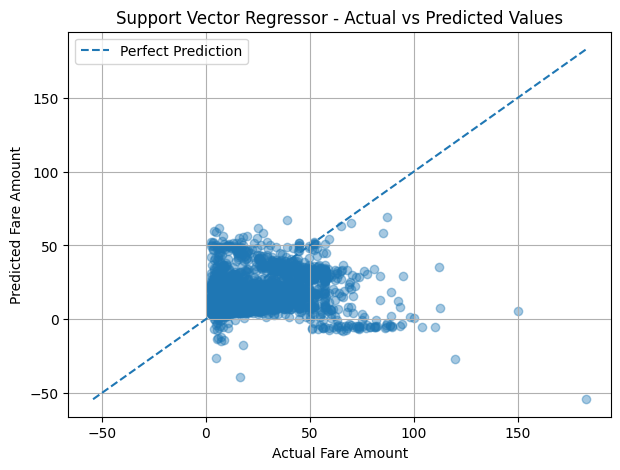

In [ ]:
# Compare actual and predicted fare amounts
comparison_df = pd.DataFrame({
    'Actual Fare': y_test.values,
    'Predicted Fare': y_pred_svr
})

display(comparison_df.head(10))

# Plot actual vs predicted values
plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    y_pred_svr,
    alpha=0.4
)

# Reference line for perfect predictions
min_value = min(y_test.min(), y_pred_svr.min())
max_value = max(y_test.max(), y_pred_svr.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--',
    label='Perfect Prediction'
)

plt.xlabel("Actual Fare Amount")
plt.ylabel("Predicted Fare Amount")
plt.title("Support Vector Regressor - Actual vs Predicted Values")
plt.legend()
plt.grid()
plt.show()

### Conclusion – Support Vector Regressor

- Achieved a Mean Absolute Error (MAE) of **4.8487**, indicating an average prediction error of approximately 4.85 fare units.
- Obtained a Mean Squared Error (MSE) of **68.1533**.
- Achieved a Root Mean Squared Error (RMSE) of **8.2555**, indicating the magnitude of prediction errors.
- Obtained an R² Score of **0.2638**, indicating that the model explains approximately **26.38%** of the variation in fare amounts.
- The model demonstrated limited predictive performance, as the relatively low R² Score indicates that it could not explain a large proportion of the variations in Uber fare amounts.

In [ ]:
# Create a regression performance table
regression_results = pd.DataFrame({
    'Algorithm': ['Linear Support Vector Regressor'],
    'MAE': [svr_mae],
    'MSE': [svr_mse],
    'RMSE': [svr_rmse],
    'R2 Score': [svr_r2]
})

display(regression_results)

,Algorithm,MAE,MSE,RMSE,R2 Score
0,Linear Support Vector Regressor,4.848676,68.153339,8.255504,0.263761


# Srabani Khuntia, 24BCSB03
# Roll No: 7, Group:E1